# BiciMAD operations optimization

Madrid’s public bike-share (BiciMAD) has a structural imbalance problem: throughout the day, high-demand stations run empty while low-traffic stations sit full. Users cannot take a bike, or cannot return one. Trucks already move bicycles periodically; the question is **where the bikes ought to be**, hour by hour, so that they spend more time being ridden and less time stranded.

This notebook is a complete, executable walkthrough of that process. The first pipeline step fills `data/raw` from the official EMT historical package when the trip and station files are not already there. The rest is the analysis and the explanation.


## 0. Problem framing and the bike utilization rate

The project statement defines **bike utilization rate** as

$$
\begin{aligned}
U
&= \frac{\text{time bikes were being used}}{\text{time they could have been used}} \\
&= \frac{\sum_k \mathrm{travel\_time}_k}{N_{\mathrm{bikes}} \times T}.
\end{aligned}
$$

A bike sitting in a dock does not contribute to the numerator. A bike that cannot be taken because its station is empty (or cannot be returned because the station is full) also fails to generate trip-minutes. So maximizing $U$ is not “keep every dock busy with parked bikes”; it is **put bikes where the next hour of demand is**.

Two complementary views are used throughout:

1. **Fleet utilization** $U$ — trip-hours over fleet-hours. In the CSV era (mid-2021 onward) the fleet size is the number of distinct `idBike` values; otherwise we use the maximum number of bikes observed at stations in a snapshot as a lower bound.
2. **Service availability** — fraction of station-hours that are neither empty (`dock_bikes = 0`) nor full (`free_bases = 0`). Lost starts $\max(0, \text{unplugs} - \text{stock})$ and lost ends $\max(0, \text{plugs} - \text{free docks})$ are the operational translation of imbalance.

The predictive target is therefore a **stock level** per station and hour, not merely net flow. Empty and full are capacity-constrained events: predicting “+3 bikes of net demand” is useless if the station already has 0 docks free. Linear programming then turns those target stocks into a feasible truck plan.


In [1]:
from __future__ import annotations

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

HERE = Path.cwd().resolve()
ROOT = HERE
for _candidate in (HERE, *HERE.parents):
    if (_candidate / "src" / "bicimad" / "__init__.py").is_file():
        ROOT = _candidate
        break
sys.path.insert(0, str(ROOT / "src"))
import os
os.chdir(ROOT)

from bicimad.config import ProjectConfig, discover_months, discover_status_files, discover_trip_files
from bicimad.perf import PerfLogger
from bicimad.quality import (
    clean_status,
    clean_trips,
    gini_coefficient,
    status_quality_report,
    trip_quality_report,
    univariate_profile,
)
from bicimad.validate import (
    assert_no_future_leakage,
    business_rule_violations,
    validate_station_hour,
    validate_status,
    validate_trips,
)
from bicimad.pipeline import run_pipeline
from bicimad.features import add_train_only_hour_of_week_means, feature_matrix
from bicimad.utilization import (
    availability_metrics,
    fleet_size_from_status,
    fleet_size_from_trips,
    fleet_utilization,
    lost_demand,
    simulate_policies,
)
from bicimad.models import (
    classification_metrics,
    demo_split,
    make_adaboost_classifier,
    make_elasticnet_regressor,
    make_extratrees_classifier,
    make_extratrees_regressor,
    make_hgb_classifier,
    make_hgb_regressor,
    make_linearsvc_classifier,
    make_linearsvr_regressor,
    make_logreg_classifier,
    make_rf_classifier,
    make_rf_regressor,
    make_mlp_classifier,
    make_mlp_regressor,
    make_ridge_regressor,
    make_xgb_classifier,
    make_xgb_regressor,
    peak_weights,
    regression_metrics,
    scores_to_proba,
    temporal_split,
)
from bicimad.optimize import redistribution_lp
from bicimad.weather import MADRID_DISTRICTS
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.pipeline import Pipeline
import joblib

# --- runtime knobs ---
DATA_SCOPE = "demo"          # "demo" | "2022" | "all"
DEMO_MONTHS = ("2022-10",)
REBUILD_PARQUET = False
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

cfg = ProjectConfig(
    root=ROOT,
    data_scope=DATA_SCOPE,
    demo_months=DEMO_MONTHS,
    rebuild_parquet=REBUILD_PARQUET,
    random_seed=RANDOM_SEED,
)
cfg.ensure_dirs()
print("project root:", ROOT)
print("scope:", cfg.data_scope)


project root: C:\Users\jejoz\Documents\Codigo\Cursos\TFG\v1
scope: demo


## 1. Data pipeline design

The raw dump is not a table. It is **three trip schemas**, **hourly station snapshots in NDJSON**, and an empty `stations_static/` folder. A pipeline that pretends otherwise will either leak timestamps or run out of RAM (the 2018–2019 trip files embed GPS tracks and weigh 0.6–1.0 GB *each*).

**Architecture** (immutable raw → columnar checkpoints → modelling table)

```text
data/
├── raw/                     immutable inputs
│   ├── trips/               three schemas, 2018-09 .. 2022-12
│   ├── status/              hourly NDJSON; 172 → 264 stations
│   ├── stations_static/     empty; catalog comes from status
│   └── mass_events/         madrid_mass_events.csv, 2018–2022
├── processed/               columnar checkpoints
│   ├── trips_*.parquet
│   ├── status_*.parquet
│   ├── stations_*.parquet
│   └── weather/             Open-Meteo, one parquet per district
├── feature_store/           station_hour_*.parquet
├── models/
└── evaluation/
```

`raw/trips/` is JSON v1 (2018-09 .. 2019-06, with GPS tracks), JSON v2 (2019-07 .. 2021-06), and CSV (2021-06 .. 2022-12). `mass_events/` lists football, concerts, fairs, and rallies. Weather is one parquet per district and date range. Each `feature_store` row is one `(station_id, hour)`.

**Stages**

1. **Acquisition** — the next cell. Yearly EMT ZIPs are unpacked into `raw/trips` and `raw/status` for the months in `DATA_SCOPE`. Files already on disk are kept.
2. **Ingestion** — month-by-month adapters; GPS `track` objects are dropped at parse time.
3. **Parsing & normalization** — timestamps to UTC, station ids to integers, `travel_time` to minutes, CSV blank separator rows skipped. June 2021 exists as both JSON and CSV; CSV wins (second-level timestamps).
4. **Temporal aggregation** — regular **hourly** grid in `Europe/Madrid`. Native resolution of both status and pre-2021 trips is the hour, so 15-minute bins would be fiction.
5. **Enrichment** — calendar, **district-level weather**, **mass events**, lags/rollings, neighbours, station clusters.
6. **Split** — strictly temporal; never shuffled.
7. **Performance** — wall time, RSS, row counts logged per stage; parquet checkpoints make re-runs cheap.

### Acquisition — station status and trips

The files come from the EMT open-data package [Históricos de BiciMAD 2017–2023](https://datos.emtmadrid.es/dataset/historicos-de-bicimad-2017_2023) (Open Data Commons Attribution). The CKAN record lists one ZIP per year on `media.emtmadrid.es`. Inside each ZIP, every month is itself a ZIP or a RAR (trips and station snapshots), plus a `__MACOSX` tree that is thrown away.

`ensure_raw_data` downloads only what `DATA_SCOPE` asks for and unpacks it into `data/raw/trips` and `data/raw/status`:

| Scope | Months fetched |
| --- | --- |
| `demo` | `DEMO_MONTHS` (default October 2022) |
| `2022` | January–December 2022 |
| `all` | Every month in the seven yearly archives, 2017-04 through 2023-02 |

A month already on disk is not downloaded again. 2017 and January–June 2018 have trips and no station snapshots; the 2023 archive stops in February and has no station file. Station months that EMT published as RAR are unpacked with `tar` (bsdtar reads RAR4). `all` is about 3 GB compressed, and the 2018–2019 trip files are much larger once the GPS tracks are inflated — `demo` is the run that finishes on a laptop.


In [2]:
from bicimad.download import ensure_raw_data

raw_report = ensure_raw_data(cfg)
display(raw_report)

EMT 2022: listing https://media.emtmadrid.es/-uHaW6iZkhG
  downloading 202210-json.zip (7.4 MB compressed)
    wrote status/202210.json (55.6 MB)
  downloading trips_22_10_October-csv.zip (21.6 MB compressed)
    trips_22_10_October-csv.zip: 21/22 MB
    wrote trips/trips_22_10_October.csv (145.6 MB)


,year,month,kind,file,bytes,action
0,2022,2022-10,status,202210.json,55603472,downloaded
1,2022,2022-10,trips,trips_22_10_October.csv,145556762,downloaded


In [3]:
inventory = discover_months(cfg)
trip_files = discover_trip_files(cfg)
status_files = discover_status_files(cfg)

inv_df = pd.DataFrame({
    "group": ["trips", "status", "both", "trips only", "status only"],
    "n_months": [len(inventory[k]) for k in ("trips", "status", "both", "trips_only", "status_only")],
    "first": [inventory[k][0] if inventory[k] else None for k in ("trips", "status", "both", "trips_only", "status_only")],
    "last": [inventory[k][-1] if inventory[k] else None for k in ("trips", "status", "both", "trips_only", "status_only")],
})
display(inv_df)

# schema eras
eras = []
for month, path in trip_files.items():
    kind = "csv" if path.suffix.lower() == ".csv" else ("json_v1" if "Usage" in path.name else "json_v2")
    eras.append({"month": month, "schema": kind, "file": path.name, "mb": round(path.stat().st_size / 1e6, 1)})
era_df = pd.DataFrame(eras)
display(era_df.groupby("schema").agg(n=("month", "size"), mb=("mb", "sum"), start=("month", "min"), end=("month", "max")))


,group,n_months,first,last
0,trips,1,2022-10,2022-10
1,status,1,2022-10,2022-10
2,both,1,2022-10,2022-10
3,trips only,0,NaN,NaN
4,status only,0,NaN,NaN


,n,mb,start,end
schema,,,,
csv,1,145.6,2022-10,2022-10


The ingest adapters live in `src/bicimad/ingest.py`. Each schema is mapped onto one canonical trip table (`start_ts`, `end_ts`, `start_station`, `end_station`, `travel_time_min`, …) and one canonical status table (`ts`, `station_id`, `dock_bikes`, `free_bases`, `total_bases`, `lat`, `lon`). Running the pipeline below executes those adapters for the months of `DATA_SCOPE`, cleans, validates, and builds the station-hour feature store.


In [4]:
perf = PerfLogger()
result = run_pipeline(cfg, perf=perf)

trips = result["trips"]
status = result["status"]
catalog = result["catalog"]
table = result["station_hour"]
months = result["months"]

print("cached:" , result.get("cached"))
print("months:", months)
print("trips:", f"{len(trips):,}", "status rows:", f"{len(status):,}", "stations:", len(catalog))
print("station-hour rows:", f"{len(table):,}")
if "wx_temp_c" in table.columns:
    print("weather coverage:", f"{table['wx_temp_c'].notna().mean():.1%}",
          "| districts:", table["district_name"].nunique(dropna=True),
          "| rain station-hours:", f"{table['wx_is_rain'].mean():.1%}")
if "evt_n" in table.columns:
    print("event station-hours (≤2 km):", f"{int((table['evt_n']>0).sum()):,}",
          f"({(table['evt_n']>0).mean():.2%} of rows)",
          "| city-hours with an event:", int((table.groupby('hour')['evt_city_n'].max()>0).sum()))
display(catalog.head())
display(table.head())


cached: False
months: ['2022-10']
trips: 354,636 status rows: 195,096 stations: 264
station-hour rows: 194,304
weather coverage: 100.0% | districts: 14 | rain station-hours: 6.9%
event station-hours (≤2 km): 0 (0.00% of rows) | city-hours with an event: 0


,station_id,name,number,address,lat,lon,total_bases,first_seen,last_seen,n_snapshots,district_id,district_name
0,1,Puerta del Sol A,1a,Puerta del Sol nº 1,40.417214,-3.701834,30,2022-10-01 00:05:05.771548+00:00,2022-10-31 23:19:18.083498+00:00,739,1,Centro
1,2,Puerta del Sol B,1b,Puerta del Sol nº 1,40.417313,-3.701603,30,2022-10-01 00:05:05.771548+00:00,2022-10-31 23:19:18.083498+00:00,739,1,Centro
2,3,Miguel Moya,2,Calle Miguel Moya nº 1,40.420589,-3.705842,24,2022-10-01 00:05:05.771548+00:00,2022-10-31 23:19:18.083498+00:00,739,1,Centro
3,4,Plaza Conde Suchil,3,Plaza del Conde del Valle de Súchil nº 3,40.430294,-3.706917,18,2022-10-01 00:05:05.771548+00:00,2022-10-31 23:19:18.083498+00:00,739,7,Chamberí
4,5,Malasaña,4,Calle Manuela Malasaña nº 5,40.428552,-3.702587,24,2022-10-01 00:05:05.771548+00:00,2022-10-31 23:19:18.083498+00:00,739,7,Chamberí


,station_id,hour,dock_bikes,free_bases,total_bases,occupancy,is_empty,is_full,activate,no_available,starts,ends,trip_minutes,net_flow,name,lat,lon,capacity_static,capacity,hour_of_day,...,lag_dock_bikes_2h,lag_dock_bikes_3h,lag_dock_bikes_24h,lag_dock_bikes_48h,lag_dock_bikes_168h,roll_mean_dock_bikes_3h,roll_std_dock_bikes_3h,roll_mean_dock_bikes_24h,roll_std_dock_bikes_24h,ewm_dock_bikes,starts_next,ends_next,net_flow_next,occupancy_next,dock_bikes_next,is_empty_next,is_full_next,target_stock,critical_next,is_critical_next
0,1,2022-10-01 02:00:00+02:00,18,9,30,0.600000,0,0,1,0,2.0,0.0,29.89,-2.0,Puerta del Sol A,40.417214,-3.701834,30,30,2,...,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,4.0,1.0,-3.0,0.500000,15,0.0,0.0,4.0,0,0
1,1,2022-10-01 03:00:00+02:00,15,12,30,0.500000,0,0,1,0,4.0,1.0,58.26,-3.0,Puerta del Sol A,40.417214,-3.701834,30,30,3,...,<NA>,<NA>,<NA>,<NA>,<NA>,18.0,NaN,18.0,NaN,18.000000,4.0,1.0,-3.0,0.400000,12,0.0,0.0,4.0,0,0
2,1,2022-10-01 04:00:00+02:00,12,15,30,0.400000,0,0,1,0,4.0,1.0,41.88,-3.0,Puerta del Sol A,40.417214,-3.701834,30,30,4,...,18,<NA>,<NA>,<NA>,<NA>,16.5,2.12132,16.5,2.121320,16.375000,3.0,0.0,-3.0,0.300000,9,0.0,0.0,3.0,0,0
3,1,2022-10-01 05:00:00+02:00,9,18,30,0.300000,0,0,1,0,3.0,0.0,43.15,-3.0,Puerta del Sol A,40.417214,-3.701834,30,30,5,...,15,18,<NA>,<NA>,<NA>,15.0,3.00000,15.0,3.000000,14.667436,6.0,0.0,-6.0,0.166667,5,0.0,0.0,6.0,0,0
4,1,2022-10-01 06:00:00+02:00,5,22,30,0.166667,0,0,1,0,6.0,0.0,114.63,-6.0,Puerta del Sol A,40.417214,-3.701834,30,30,6,...,12,15,<NA>,<NA>,<NA>,12.0,3.00000,13.5,3.872983,12.878448,0.0,2.0,2.0,0.000000,0,1.0,0.0,0.0,1,1


## 2. Data quality

A quality audit is run **before and after** cleaning, on six dimensions: completeness, validity, consistency, uniqueness, coverage/timeliness, and an accuracy proxy (empty/full rates, trip vs. inventory consistency).

Cleaning rules (and why they exist):

| Rule | Rationale |
|---|---|
| Drop trips with duration outside **[1 min, 4 h]** | Sub-minute events are dock glitches; multi-hour trips are forgotten bikes / maintenance, not demand. |
| Drop dockless `FREE` trips from the station table | They have no station id; they still count in fleet utilization. |
| Drop same-station loops shorter than 3 minutes | Almost certainly failed unlocks. |
| Clip `dock_bikes` to `total_bases` | Occupancy cannot exceed capacity; a few snapshots do. |
| Drop coordinates outside the Madrid bounding box | Protects maps and neighbour features. |

Every rule logs how many rows it removes so the final sample size is explainable.


Trip quality (input to cleaner)


,dimension,check,n_flagged,pct
0,completeness,missing start_ts,0,0.000
1,completeness,missing start_station,1389,0.320
2,completeness,missing end_station,1793,0.413
3,completeness,missing travel_time_min,0,0.000
4,validity,travel_time < 1.0 min,67749,15.617
5,validity,travel_time > 240.0 min,1274,0.294
6,consistency,same origin and destination,87561,20.184
7,coverage,non-station (dockless/FREE) trips,1793,0.413
8,uniqueness,duplicate trip keys,13,0.003


Status quality (input to cleaner)


,dimension,check,n_flagged,pct
0,completeness,missing ts,0,0.000
1,completeness,missing station_id,0,0.000
2,completeness,missing dock_bikes,0,0.000
3,validity,dock_bikes > total_bases,0,0.000
4,validity,dock_bikes < 0,0,0.000
5,consistency,bikes+free > capacity + tolerance,0,0.000
6,validity,coordinates outside Madrid bbox,0,0.000
7,coverage,inactive stations (activate=0),0,0.000
8,accuracy,empty snapshots (dock_bikes=0),13174,6.753
9,accuracy,full snapshots (free_bases=0),11285,5.784


Trip cleaning impact


,rule,n_before_or_current,n_dropped,n_remaining,pct_of_input_dropped_cum
0,input,433810,0,433810,0.000
1,drop missing timestamp or duration,433810,0,433810,0.000
2,"drop travel_time outside [1 min, 4 h]",433810,69023,364787,15.911
3,drop dockless / missing station ids,364787,1863,362924,16.340
4,drop near-zero same-station loops (<3 min),362924,8277,354647,18.248
5,drop exact duplicates,354647,11,354636,18.251
6,output,354636,79174,275462,36.502


Status cleaning impact


,rule,n_before_or_current,n_dropped,n_remaining
0,input,195096,0,195096
1,drop missing ts or station_id,195096,0,195096
2,drop zero/missing capacity,195096,0,195096
3,clip dock_bikes to capacity,195096,0,195096
4,drop coordinates outside Madrid bbox,195096,0,195096


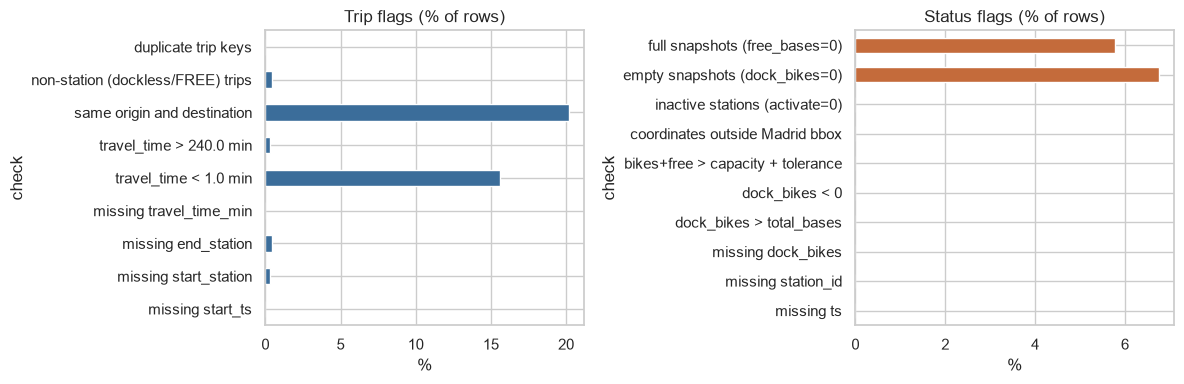

In [5]:
# Recompute quality on the *raw* frames when this was a fresh run; otherwise audit the cleaned ones.
trips_raw = result.get("trips_raw", trips)
status_raw = result.get("status_raw", status)

print("Trip quality (input to cleaner)")
q_trips = trip_quality_report(trips_raw)
display(q_trips)

print("Status quality (input to cleaner)")
q_status = status_quality_report(status_raw)
display(q_status)

if "trip_impact" in result:
    print("Trip cleaning impact")
    display(result["trip_impact"])
    print("Status cleaning impact")
    display(result["status_impact"])
else:
    print("Loaded from parquet — re-running cleaners on cached tables for the impact log.")
    _, trip_impact = clean_trips(trips)
    _, status_impact = clean_status(status)
    display(trip_impact)
    display(status_impact)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
q_trips.plot.barh(x="check", y="pct", ax=axes[0], legend=False, color="#3b6d9a")
axes[0].set_title("Trip flags (% of rows)")
axes[0].set_xlabel("%")
q_status.plot.barh(x="check", y="pct", ax=axes[1], legend=False, color="#c46b3b")
axes[1].set_title("Status flags (% of rows)")
axes[1].set_xlabel("%")
plt.tight_layout()
plt.show()


## 3. Data validation

Quality *describes* problems. Validation *gates* the pipeline.

Three layers run after cleaning:

1. **Schema (Pandera)** — required columns, dtypes, value ranges (`travel_time_min ∈ [1, 240]`, occupancy ∈ [0, 1], coordinates inside Madrid).
2. **Business rules** — origins/destinations must exist in the station catalog derived from status; `dock_bikes + free_bases` may exceed capacity by at most 2 (booking slack); snapshot gaps > 2.5 h are flagged, not filled.
3. **Temporal / leakage** — `starts_next` must not collapse onto `starts` (that would mean we forgot to `shift(-1)`). Hour-of-week means are fit on **train only**.

Critical schema failures would stop a production job. Here we surface a violations table so the thesis can discuss them.


In [6]:
v_trips = validate_trips(trips)
v_status = validate_status(status)
v_hour = validate_station_hour(table)
v_biz = business_rule_violations(trips, status, catalog)

print("Pandera — trips")
display(v_trips if len(v_trips) else pd.DataFrame({"result": ["pass"]}))
print("Pandera — status")
display(v_status if len(v_status) else pd.DataFrame({"result": ["pass"]}))
print("Pandera — station-hour")
display(v_hour if len(v_hour) else pd.DataFrame({"result": ["pass"]}))
print("Business rules")
display(v_biz)

assert_no_future_leakage(table)
print("Leakage check passed: starts_next is not a copy of starts.")


Pandera — trips


,result
0,pass


Pandera — status


,result
0,pass


Pandera — station-hour


,result
0,pass


Business rules


,table,rule,n_flagged,action
0,trips,origin not in station catalog,0,quarantine if systemic
1,trips,dest not in station catalog,0,quarantine if systemic
2,status,bikes+free exceed capacity+tolerance,0,allow booking slack
3,status,snapshot gaps > 2.5 h,1,do not interpolate across outages


Leakage check passed: starts_next is not a copy of starts.


## 4. Data pipeline performance

Twelve gigabytes of nested JSON will not fit in a naïve `pd.read_json`. The performance contract of this pipeline is:

- parse **line by line**, drop GPS tracks immediately;
- write **monthly / scope-level parquet**;
- log **wall time, peak RSS, row counts** at every stage.

The plot below is the reproducibility artefact: anyone re-running the notebook can see whether a change made ingest 10× slower.


,stage,seconds,rss_start_mb,rss_end_mb,rss_delta_mb,months,rows
0,ingest_trips,23.662,239.6,504.4,264.8,1.0,433810
1,ingest_status,6.300,504.4,434.7,-69.7,1.0,195096
2,clean_trips,0.671,434.7,514.5,79.8,NaN,354636
3,clean_status,0.058,514.5,529.5,15.0,NaN,195096
4,station_catalog,0.414,529.5,530.4,0.9,NaN,264
5,validate,0.504,530.4,489.3,-41.2,NaN,4
6,station_hour_grid,2.445,489.3,530.4,41.1,NaN,194304
7,calendar_features,1.680,530.4,547.8,17.4,NaN,194304
8,weather_features,8.560,547.8,560.2,12.4,NaN,194304
9,event_features,0.111,560.2,582.4,22.3,NaN,0


wrote C:\Users\jejoz\Documents\Codigo\Cursos\TFG\v1\data\evaluation\pipeline_perf_demo.csv


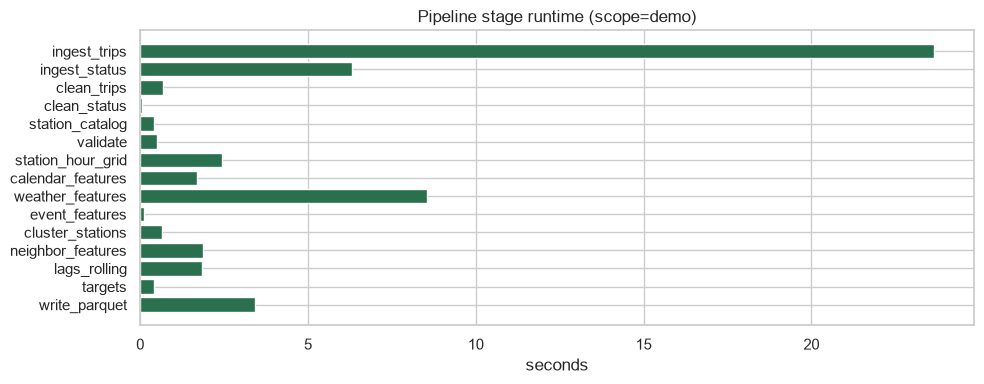

In [7]:
perf_df = result["perf"].to_frame()
display(perf_df)
perf_path = cfg.eval_dir / f"pipeline_perf_{cfg.data_scope}.csv"
perf_df.to_csv(perf_path, index=False)
print("wrote", perf_path)

fig, ax = plt.subplots(figsize=(10, 4))
plot_df = perf_df.dropna(subset=["seconds"]).copy()
ax.barh(plot_df["stage"], plot_df["seconds"], color="#2a6f4e")
ax.set_xlabel("seconds")
ax.set_title(f"Pipeline stage runtime (scope={cfg.data_scope})")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


## 5. Statistical profiling

Before drawing maps we need the shape of the distributions: travel time is right-skewed (short urban hops plus a long tail of outliers we already clipped), occupancy is U-shaped at some stations (they slam empty or full) and unimodal at others, and demand is heavily concentrated on a subset of the network (Gini).


,variable,n,mean,std,min,p01,p05,p25,median,p75,p95,p99,max,skew,kurtosis
0,travel_time_min,354636,14.310,8.921,1.0,2.83,4.5,8.300,12.280,17.780,30.770,50.530,59.98,1.872,5.001
1,hourly_starts,194304,1.819,2.315,0.0,0.00,0.0,0.000,1.000,3.000,6.000,10.000,22.00,1.875,4.656
2,hourly_ends,194304,1.819,2.367,0.0,0.00,0.0,0.000,1.000,3.000,7.000,11.000,25.00,2.062,5.925
3,hourly_net_flow,194304,-0.001,2.236,-18.0,-6.00,-4.0,-1.000,0.000,1.000,4.000,7.000,18.00,0.111,4.517
4,occupancy,194304,0.366,0.251,0.0,0.00,0.0,0.167,0.333,0.542,0.833,0.958,1.00,0.460,-0.625
5,dock_bikes,194304,8.750,6.054,0.0,0.00,0.0,4.000,8.000,13.000,20.000,23.000,30.00,0.482,-0.578


Gini coefficient of station demand (starts): 0.281
1.0 = all trips from one station; 0.0 = perfectly even. Bike-share networks are typically 0.4–0.6.


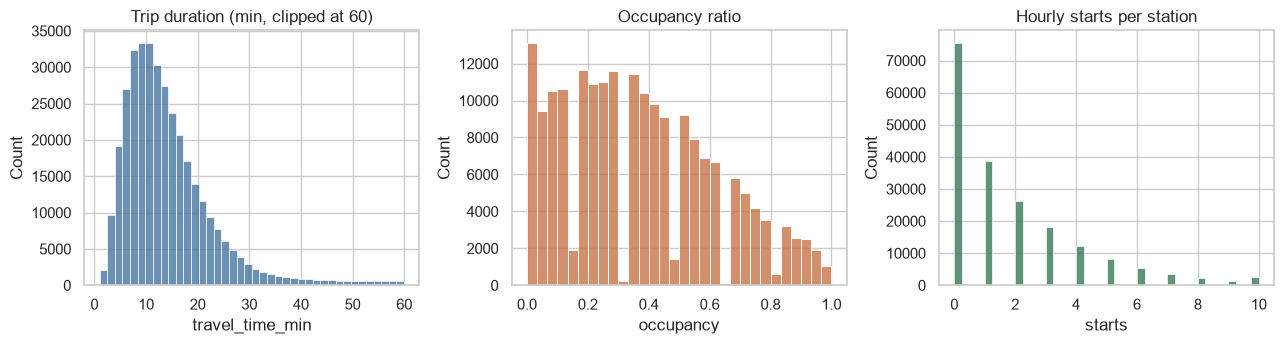

In [8]:
profiles = pd.DataFrame(
    [
        univariate_profile(trips["travel_time_min"], "travel_time_min"),
        univariate_profile(table["starts"], "hourly_starts"),
        univariate_profile(table["ends"], "hourly_ends"),
        univariate_profile(table["net_flow"], "hourly_net_flow"),
        univariate_profile(table["occupancy"], "occupancy"),
        univariate_profile(table["dock_bikes"], "dock_bikes"),
    ]
)
display(profiles.round(3))

station_demand = table.groupby("station_id")["starts"].sum()
print(f"Gini coefficient of station demand (starts): {gini_coefficient(station_demand.to_numpy()):.3f}")
print("1.0 = all trips from one station; 0.0 = perfectly even. Bike-share networks are typically 0.4–0.6.")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
sns.histplot(trips["travel_time_min"].clip(upper=60), bins=40, ax=axes[0], color="#3b6d9a")
axes[0].set_title("Trip duration (min, clipped at 60)")
sns.histplot(table["occupancy"].dropna(), bins=30, ax=axes[1], color="#c46b3b")
axes[1].set_title("Occupancy ratio")
sns.histplot(table["starts"].clip(upper=table["starts"].quantile(0.99)), bins=40, ax=axes[2], color="#2a6f4e")
axes[2].set_title("Hourly starts per station")
plt.tight_layout()
plt.show()


## 6. Exploratory data analysis

EDA here is not a gallery. Each plot is a modelling decision.

### 6.1 System overview and baseline utilization


unique idBike: 3100 | max docked bikes in a snapshot: 2310
fleet size used for U: 3100
Fleet utilization: {'trip_hours': 84581.5213, 'n_bikes': 3100.0, 'window_hours': 764.6867, 'utilization': 0.0357, 'utilization_pct': 3.568}
Availability: {'station_hours': 194304, 'empty_hours': 13137, 'full_hours': 11250, 'empty_rate': 0.0676, 'full_rate': 0.0579, 'neither_empty_nor_full_rate': 0.9122}


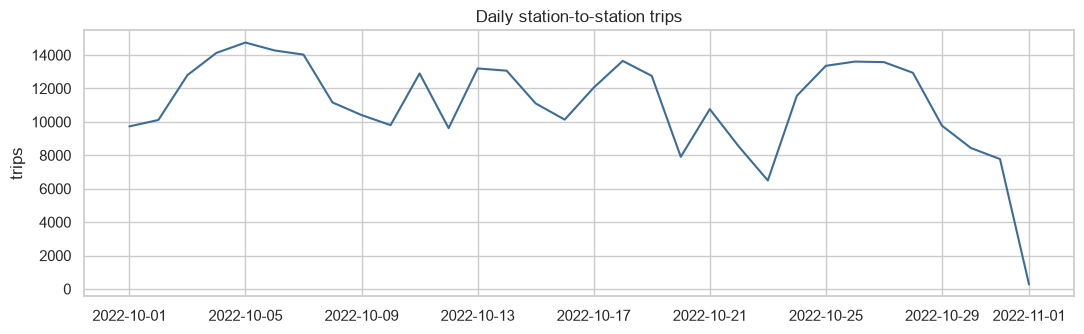

In [9]:
n_bikes_ids = fleet_size_from_trips(trips)
n_bikes_docked = fleet_size_from_status(status)
n_bikes = n_bikes_ids or n_bikes_docked
print(f"unique idBike: {n_bikes_ids} | max docked bikes in a snapshot: {n_bikes_docked:.0f}")
print(f"fleet size used for U: {n_bikes:.0f}")

t0, t1 = trips["start_ts"].min(), trips["end_ts"].max()
window_h = (t1 - t0).total_seconds() / 3600.0
U = fleet_utilization(trips, n_bikes=n_bikes, window_hours=window_h)
print("Fleet utilization:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in U.items()})

avail = availability_metrics(table)
print("Availability:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in avail.items()})

daily = (
    trips.assign(day=trips["start_ts"].dt.tz_convert("Europe/Madrid").dt.date)
    .groupby("day")
    .size()
    .rename("trips")
    .reset_index()
)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily["day"], daily["trips"], color="#3b6d9a")
ax.set_title("Daily station-to-station trips")
ax.set_ylabel("trips")
plt.tight_layout()
plt.show()


### 6.2 Temporal patterns

Commuter systems have two peaks on weekdays (morning outbound, evening return) and a flatter weekend. That is why we encode hour and day-of-week cyclically, and why regression error is **weighted** on 07–10h and 17–20h later.


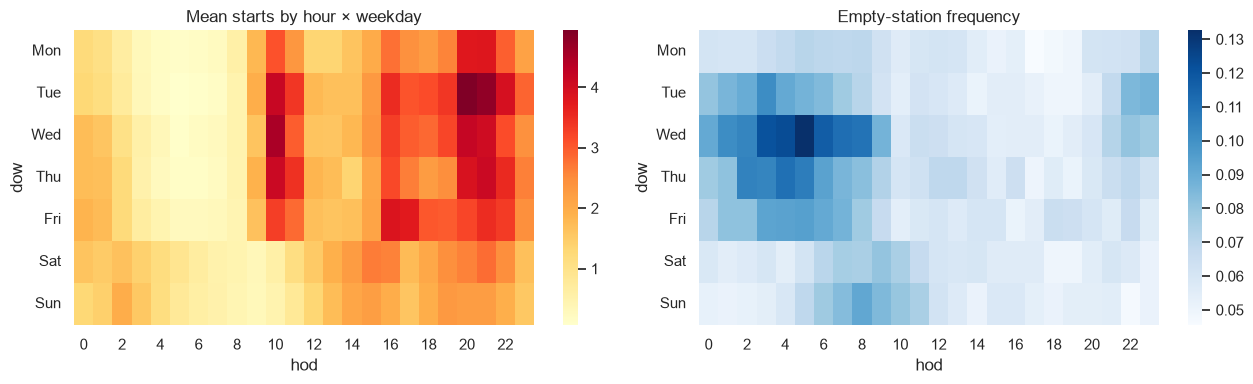

In [10]:
tmp = table.copy()
tmp["hod"] = tmp["hour_of_day"]
tmp["dow"] = tmp["dow"]
heat_starts = tmp.pivot_table(index="dow", columns="hod", values="starts", aggfunc="mean")
heat_empty = tmp.pivot_table(index="dow", columns="hod", values="is_empty", aggfunc="mean")
dow_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(heat_starts, ax=axes[0], cmap="YlOrRd")
axes[0].set_yticklabels(dow_labels, rotation=0)
axes[0].set_title("Mean starts by hour × weekday")
sns.heatmap(heat_empty, ax=axes[1], cmap="Blues")
axes[1].set_yticklabels(dow_labels, rotation=0)
axes[1].set_title("Empty-station frequency")
plt.tight_layout()
plt.show()


### 6.3 Spatial imbalance

Stations that empty in the morning and fill in the evening (residential) are the opposite of stations that fill in the morning (employment / metro hubs). Redistribution trucks should move **against** that tide before the peak, not after users have already been denied a bike.


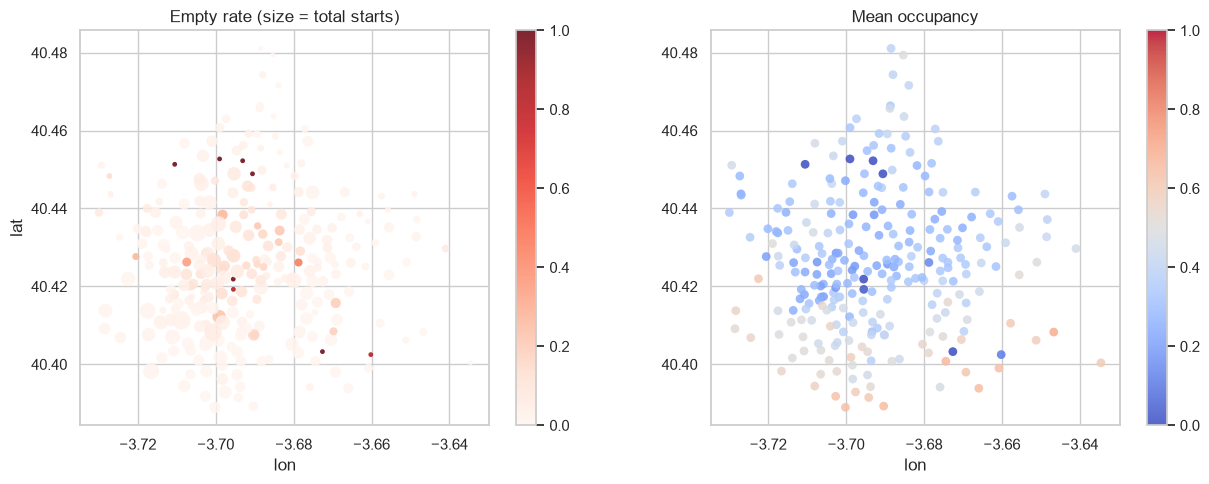

,station_id,name,empty_rate,full_rate,starts,occ
19,20,Prim,1.000000,1.000000,0.0,0.000000
83,89,Valderribas,1.000000,1.000000,0.0,0.000000
136,142,General Perón 1,1.000000,1.000000,0.0,0.000000
137,143,General Perón con Poeta Joan Maragall,1.000000,1.000000,0.0,0.000000
141,147,Castellana frente a Hermanos Pinzón,1.000000,1.000000,0.0,0.000000
239,245,Pablo Iglesias,1.000000,1.000000,0.0,0.000000
20,21,Banco de España A,0.835598,0.786685,188.0,0.025317
227,233,Doctor Lozano,0.826087,0.828804,62.0,0.112942


In [11]:
station_stats = (
    table.groupby(["station_id", "name", "lat", "lon", "capacity"], dropna=False)
    .agg(
        starts=("starts", "sum"),
        ends=("ends", "sum"),
        occ=("occupancy", "mean"),
        empty_rate=("is_empty", "mean"),
        full_rate=("is_full", "mean"),
    )
    .reset_index()
)
morning = table[table["hour_of_day"].between(7, 10)].groupby("station_id")["starts"].mean().rename("morning_starts")
evening = table[table["hour_of_day"].between(17, 20)].groupby("station_id")["starts"].mean().rename("evening_starts")
station_stats = station_stats.merge(morning, on="station_id", how="left").merge(evening, on="station_id", how="left")
station_stats["commute_sign"] = station_stats["morning_starts"] - station_stats["evening_starts"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc0 = axes[0].scatter(
    station_stats["lon"], station_stats["lat"],
    c=station_stats["empty_rate"], s=np.clip(station_stats["starts"] / station_stats["starts"].max() * 180, 12, 180),
    cmap="Reds", alpha=0.85, edgecolors="none",
)
axes[0].set_title("Empty rate (size = total starts)")
axes[0].set_xlabel("lon"); axes[0].set_ylabel("lat")
plt.colorbar(sc0, ax=axes[0], fraction=0.046)
sc1 = axes[1].scatter(
    station_stats["lon"], station_stats["lat"],
    c=station_stats["occ"], s=40, cmap="coolwarm", vmin=0, vmax=1, alpha=0.85, edgecolors="none",
)
axes[1].set_title("Mean occupancy")
axes[1].set_xlabel("lon")
plt.colorbar(sc1, ax=axes[1], fraction=0.046)
for ax in axes:
    ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

display(station_stats.nlargest(8, "empty_rate")[["station_id", "name", "empty_rate", "full_rate", "starts", "occ"]])


### 6.4 Origin–destination flows and station clusters


Top 10 OD pairs


,start_station,end_station,n,origin,dest
0,64,64,262,Plaza de la Independencia,Plaza de la Independencia
1,175,175,210,Segovia 45,Segovia 45
2,220,220,180,Marqués de Vadillo,Marqués de Vadillo
3,132,132,162,Paseo de la Florida,Paseo de la Florida
4,181,134,148,Puente Praga,Paseo de la Esperanza
5,224,224,148,Puerta del Ángel,Puerta del Ángel
6,57,57,147,Plaza de Lavapiés,Plaza de Lavapiés
7,43,43,141,Plaza de la Cebada,Plaza de la Cebada
8,220,132,139,Marqués de Vadillo,Paseo de la Florida
9,220,43,139,Marqués de Vadillo,Plaza de la Cebada


Cluster sizes (k-means on 24-h start/end profiles):


,n_stations
cluster,
0,82
1,34
2,64
3,84


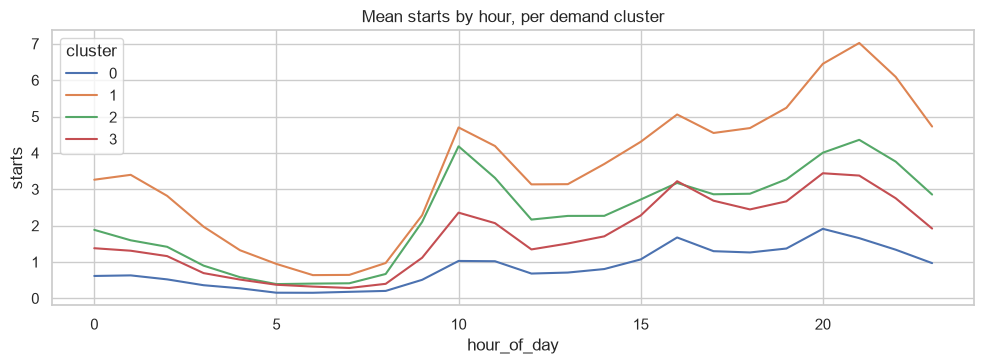

In [12]:
od = (
    trips.groupby(["start_station", "end_station"], as_index=False)
    .size()
    .rename(columns={"size": "n"})
    .sort_values("n", ascending=False)
)
od = od.merge(catalog[["station_id", "name"]].rename(columns={"station_id": "start_station", "name": "origin"}), on="start_station")
od = od.merge(catalog[["station_id", "name"]].rename(columns={"station_id": "end_station", "name": "dest"}), on="end_station")
print("Top 10 OD pairs")
display(od.head(10))

print("Cluster sizes (k-means on 24-h start/end profiles):")
display(table.groupby("cluster")["station_id"].nunique().rename("n_stations").to_frame())
cluster_profile = table.groupby(["cluster", "hour_of_day"])["starts"].mean().unstack("cluster")
cluster_profile.plot(figsize=(10, 3.8), title="Mean starts by hour, per demand cluster")
plt.ylabel("starts")
plt.tight_layout()
plt.show()


### 6.5 Target exploration

Two facts drive the labels:

- Next-hour emptiness is much more likely when current occupancy is already low — a lag of occupancy is not optional.
- The stock that would have served next-hour demand is **not** equal to current `dock_bikes`. That gap is the rebalancing opportunity.


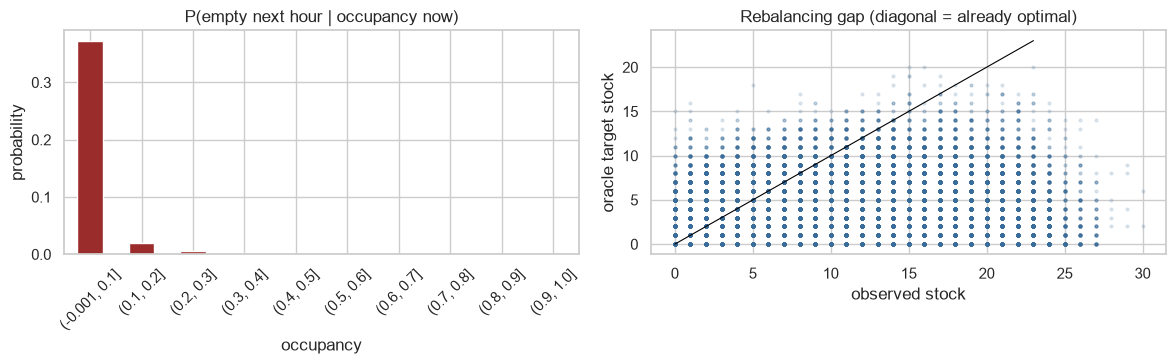

In [13]:
sample = table.dropna(subset=["occupancy", "is_empty_next", "target_stock"])
bins = pd.cut(sample["occupancy"], bins=np.linspace(0, 1, 11), include_lowest=True)
p_empty = sample.groupby(bins, observed=False)["is_empty_next"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
p_empty.plot.bar(ax=axes[0], color="#9b2c2c")
axes[0].set_title("P(empty next hour | occupancy now)")
axes[0].set_ylabel("probability")
axes[0].tick_params(axis="x", rotation=45)
axes[1].scatter(sample["dock_bikes"], sample["target_stock"], s=4, alpha=0.15, color="#3b6d9a")
axes[1].set_xlabel("observed stock")
axes[1].set_ylabel("oracle target stock")
axes[1].set_title("Rebalancing gap (diagonal = already optimal)")
lim = max(sample["dock_bikes"].quantile(0.99), sample["target_stock"].quantile(0.99))
axes[1].plot([0, lim], [0, lim], color="black", lw=0.8)
plt.tight_layout()
plt.show()


### 6.6 District-level weather

BiciMAD stations are mapped to Madrid’s 21 official districts by nearest centroid, then joined to **hourly weather at that district’s centroid** from the Open-Meteo historical archive (ERA5/ERA5-Land reanalysis, `timezone=Europe/Madrid`).

That is district-level rather than a single city-wide series: Centro and Barajas can (and do) differ. Reanalysis grid cells are ~9–25 km, so adjacent central districts sometimes share a temperature; rain, wind and the outskirts still move independently. Weather is known at hour $t$ and is used to predict $t+1$ — no future weather leaks into the features. Files are cached under `data/processed/weather/` so re-runs stay offline.


district lookup size: 21 | districts present: 14


,n_stations,mean_temp_c,rain_hour_share,mean_precip_mm,mean_starts
district_name,,,,,
Centro,59,17.811,0.065,0.044,2.224
Salamanca,53,17.285,0.072,0.046,1.562
Chamberí,46,17.285,0.072,0.046,2.137
Arganzuela,28,17.811,0.065,0.044,2.116
Retiro,21,17.811,0.065,0.044,2.033
Tetuán,20,17.285,0.072,0.046,1.115
Chamartín,11,17.285,0.072,0.046,1.025
Ciudad Lineal,7,17.285,0.072,0.046,1.159
Moratalaz,7,17.811,0.065,0.044,1.003


corr(starts, temp)   0.558
corr(starts, precip) -0.051


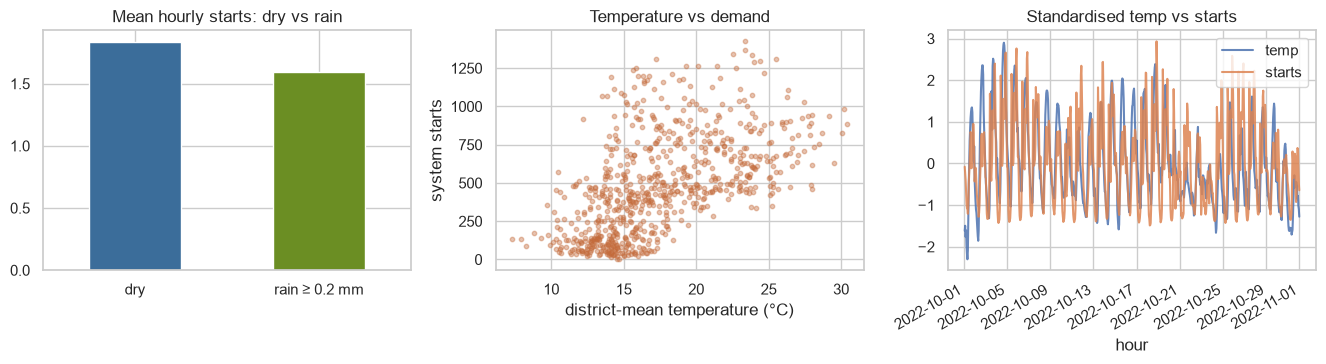

In [14]:
assert "wx_temp_c" in table.columns, "Weather columns missing — re-run the pipeline cell."
print("district lookup size:", len(MADRID_DISTRICTS), "| districts present:", table["district_name"].nunique())
wx_summary = (
    table.groupby("district_name", dropna=False)
    .agg(
        n_stations=("station_id", "nunique"),
        mean_temp_c=("wx_temp_c", "mean"),
        rain_hour_share=("wx_is_rain", "mean"),
        mean_precip_mm=("wx_precip_mm", "mean"),
        mean_starts=("starts", "mean"),
    )
    .sort_values("n_stations", ascending=False)
)
display(wx_summary.round(3))

hourly_sys = (
    table.groupby("hour", as_index=False)
    .agg(starts=("starts", "sum"), temp=("wx_temp_c", "mean"), precip=("wx_precip_mm", "mean"), rain=("wx_is_rain", "max"))
)
print("corr(starts, temp)  ", hourly_sys["starts"].corr(hourly_sys["temp"]).round(3))
print("corr(starts, precip)", hourly_sys["starts"].corr(hourly_sys["precip"]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
table.groupby("wx_is_rain")["starts"].mean().rename({0: "dry", 1: "rain ≥ 0.2 mm"}).plot.bar(
    ax=axes[0], color=["#3b6d9a", "#6b8e23"], rot=0
)
axes[0].set_title("Mean hourly starts: dry vs rain")
axes[0].set_xlabel("")
axes[1].scatter(hourly_sys["temp"], hourly_sys["starts"], s=10, alpha=0.4, color="#c46b3b")
axes[1].set_xlabel("district-mean temperature (°C)")
axes[1].set_ylabel("system starts")
axes[1].set_title("Temperature vs demand")
hourly_sys.set_index("hour")[["temp", "starts"]].apply(lambda s: (s - s.mean()) / s.std()).plot(
    ax=axes[2], alpha=0.85
)
axes[2].set_title("Standardised temp vs starts")
axes[2].legend(["temp", "starts"], loc="upper right")
plt.tight_layout()
plt.show()


### 6.7 Mass events

`data/raw/mass_events/madrid_mass_events.csv` lists 199 football matches, concerts, fairs and rallies (2018–2022) with venue coordinates and attendance. A stadium emptying 60,000 people does not raise demand uniformly: it hits **stations within ~2 km**, and it hits them **before kick-off** (arrivals) and **after the final whistle** (departures).

Each event is expanded to local hours covering a 2 h pre-buffer, the event itself, and a 2 h post-buffer. Every station-hour then gets proximity aggregates (count, attendance, min distance, type flags). City-wide counts (`evt_city_*`) capture system effects even for stations far from the venue (IFEMA, a Clásico).


nearby station-hours: 0 of 194,304
mean starts | nearby vs not: nan vs 1.82
mean starts by phase (nearby):
Series([], Name: starts, dtype: float64)


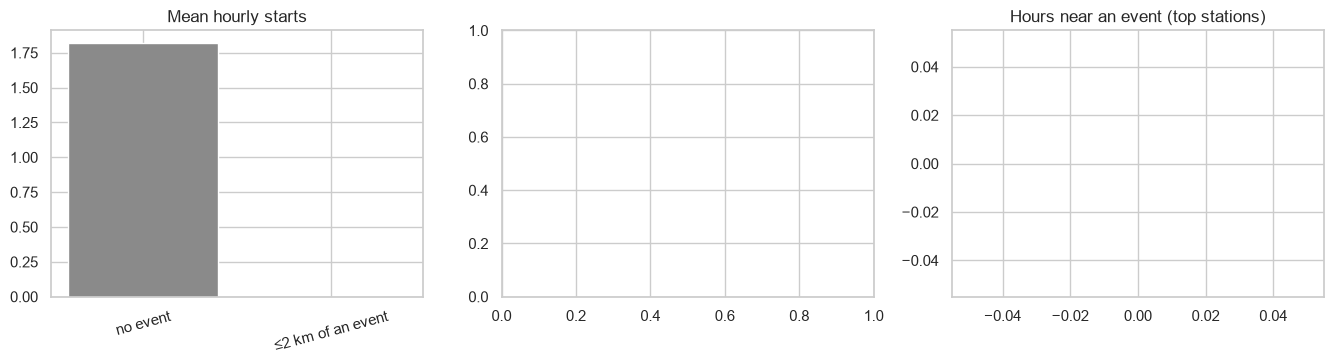

,station_id,name,n_hours,mean_starts,min_km


In [15]:
assert "evt_n" in table.columns, "Event columns missing — re-run the pipeline cell."
near = table[table["evt_n"] > 0]
print("nearby station-hours:", f"{len(near):,}", "of", f"{len(table):,}")
print("mean starts | nearby vs not:",
      f"{near['starts'].mean():.2f} vs {table.loc[table['evt_n']==0, 'starts'].mean():.2f}")
phase = table.melt(
    id_vars=["starts"],
    value_vars=["evt_pre", "evt_during", "evt_post"],
    var_name="phase",
    value_name="flag",
)
phase = phase[phase["flag"] == 1].groupby("phase")["starts"].mean()
print("mean starts by phase (nearby):")
print(phase.rename(index=lambda s: s.replace("evt_", "")).round(3))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
axes[0].bar(["no event", "≤2 km of an event"], [
    table.loc[table["evt_n"]==0, "starts"].mean(),
    near["starts"].mean() if len(near) else 0,
], color=["#8a8a8a", "#9b2c2c"])
axes[0].set_title("Mean hourly starts")
axes[0].tick_params(axis="x", rotation=15)
if len(phase):
    phase.plot.bar(ax=axes[1], color="#c46b3b", rot=0)
    axes[1].set_title("Starts by event phase")
    axes[1].set_xticklabels([x.replace("evt_", "") for x in phase.index])
hot = (
    near.groupby(["station_id", "name"], as_index=False)
    .agg(n_hours=("hour", "nunique"), mean_starts=("starts", "mean"), min_km=("evt_min_dist_km", "min"))
    .sort_values("n_hours", ascending=False)
    .head(8)
)
axes[2].barh(hot["name"].iloc[::-1], hot["n_hours"].iloc[::-1], color="#3b6d9a")
axes[2].set_title("Hours near an event (top stations)")
plt.tight_layout()
plt.show()
display(hot.round(2))


### EDA insights (modelling consequences)

1. **Hourly grain** — status and pre-2021 trips are hourly; finer bins would overfit noise.
2. **Stock, not flow, is the headline target** — capacity turns the same net flow into empty or full depending on the starting inventory.
3. **Lags at 1 h, 24 h, 168 h** match the autocorrelation of commuting.
4. **Criticality classification** is the operational alert layer (will this station fail in the next hour?).
5. **Clusters** give the LP a natural subset: rebalance inside a cluster first, where distances are short.
6. **District weather** (especially rain and temperature) belongs in the model: demand drops when it rains, even at the same hour-of-week.
7. **Mass events** are local and phased: a Bernabéu kick-off empties Chamartín/Tetuán stations two hours *before* 21:00, not the whole city at once.


## 7. Feature engineering

One row = one `(station_id, hour)` at time $t$. Every feature must be known at $t$. The labels live at $t+1$.

**Regression labels**

$$
\mathrm{target\_stock}_{i,t}
= \operatorname{clip}\bigl(\mathrm{starts}_{i,t+1},\, 0,\, C_i - \mathrm{ends}_{i,t+1}\bigr)
$$

This is the *oracle* number of bikes that would have served next-hour unplugs while leaving docks for next-hour returns. We also keep `starts_next` and `ends_next` because the linear program needs both.

**Classification label**

`critical_next`: `0 = ok`, `1 = empty next hour`, `2 = full next hour`. A binary `is_critical_next` is used for the three-model comparison so precision-recall is well-defined.

**Feature groups** (see `feature_matrix()`): calendar + cyclic encodings + Spanish/Madrid holidays; **district-level weather**; **mass events** (proximity, attendance, pre/during/post, type); lags 1, 2, 3, 24, 48, 168 h; rolling mean/std 3 h and 24 h; EWM; capacity, coordinates, k-means cluster; 5-nearest-neighbour occupancy and net flow; system-wide occupancy; train-only hour-of-week means.

Weather is fetched once from Open-Meteo and cached as parquet, so later runs do not need the network.


### Feature catalog

Every modelling column is listed below. Features are known at the end of hour $t$. Labels describe hour $t+1$. Lags, rollings and EWMs are computed **per station** with an explicit `shift(1)` so they never see the current hour, let alone the future. Hour-of-week means are fit on **train only**.

#### Grain (not fed to the models)

| Column | What it is |
|---|---|
| `station_id` | Integer BiciMAD station identifier. |
| `hour` | Start of the local (`Europe/Madrid`) hour this row describes. DST-safe floor. |
| `name` | Station name, from the latest status snapshot. Used in plots and the LP move list, not as a predictor. |

#### Contemporaneous station state at hour $t$

| Column | What it is | Why it is engineered |
|---|---|---|
| `starts` | Count of unplugs (trips that **left** this station) during hour $t$. | Immediate demand. Predicting $t+1$ from the hour that just finished is the operational setting. |
| `ends` | Count of plugs (trips that **arrived**) during hour $t$. | Return pressure; together with `starts` it is the observed flow. |
| `net_flow` | `ends − starts`. Positive = the station gained bikes. | Compresses imbalance into one signed number. |
| `trip_minutes` | Sum of trip durations for unplugs in hour $t$. | Utilization numerator at station-hour grain. Not in the default model matrix (collinear with `starts` × duration). |
| `dock_bikes` | Bikes sitting in docks at the last status snapshot of the hour (forward-filled). | Current inventory — the thing redistribution would change. |
| `free_bases` | Empty docks at that snapshot. | Dual of inventory; full-station risk. |
| `total_bases` | Dock capacity reported in that snapshot. | Time-varying capacity (stations were resized). |
| `capacity` | `total_bases`, falling back to the catalog’s last known capacity. | Hard upper bound for stock targets and the LP. |
| `occupancy` | `dock_bikes / total_bases` ∈ [0, 1]. | Scale-free fill level; comparable across 18-dock and 30-dock stations. |
| `is_empty` | 1 if `dock_bikes == 0`. | Binary “no bike to take” flag; strong lag-1 predictor of `is_empty_next`. |
| `is_full` | 1 if `free_bases == 0`. | Binary “no dock to return to” flag. |
| `activate` | 1 if the station is in service. | Inactive stations should not generate demand. |
| `no_available` | Status flag that the station is marked unavailable. | Outage vs. true empty. |

#### Calendar and cyclic time

Commuting is 24 h- and 7-day-periodic. Raw `hour_of_day = 23` next to `0` would look far apart to a tree/MLP; sine/cosine wrap the clock.

| Column | What it is | Why it is engineered |
|---|---|---|
| `hour_of_day` | 0–23 in Madrid local time. | Peak vs. off-peak regime. |
| `dow` | Monday = 0 … Sunday = 6. | Weekday commute vs. weekend leisure. |
| `month` | 1–12. | Seasonal demand (heat, holidays, academic calendar). |
| `is_weekend` | 1 if `dow ≥ 5`. | Explicit weekend switch; trees can split on it directly. |
| `is_holiday` | 1 if the date is a Spanish / Community of Madrid public holiday (`holidays` package, `ES-MD`). | Holiday demand looks like a Sunday, not like the same weekday last week. |
| `hour_sin`, `hour_cos` | $\sin(2\pi h/24)$, $\cos(2\pi h/24)$. | Circular encoding of hour so 23:00 is close to 00:00. |
| `dow_sin`, `dow_cos` | $\sin(2\pi d/7)$, $\cos(2\pi d/7)$. | Same idea for the week. |

#### Station identity and spatial context

| Column | What it is | Why it is engineered |
|---|---|---|
| `lat`, `lon` | WGS84 coordinates from the station catalog. | Location proxy (centre vs. periphery, elevation of demand). |
| `cluster` | k-means, $k = 4$, label on the 24-h mean start **and** end profile. | Groups residential “empty in the morning” stations vs. employment hubs. Used as a feature and as an LP subset. |
| `nbr_occ_mean` | Mean occupancy of the 5 geographically nearest other stations, same hour (haversine). | Imbalance often propagates to neighbours; a full neighbour dumps returns here. |
| `nbr_net_mean` | Mean net flow of those 5 neighbours, same hour. | Short-term surge arriving from next door. |
| `sys_occ_mean` | System-wide mean occupancy in that hour. | Global tightness of the fleet (rainy Monday vs. empty August). |

#### Lags (same station, past hours)

Built for each of `starts`, `ends`, `net_flow`, `occupancy`, `dock_bikes`. All are `groupby(station_id).shift(lag)` — no leakage across stations or into the future.

| Column pattern | Lag | What it captures |
|---|---|---|
| `lag_{col}_1h` | 1 hour | Persistence: an emptying station is still emptying. |
| `lag_{col}_2h` | 2 hours | Very short trend (start of the morning peak). |
| `lag_{col}_3h` | 3 hours | Same, one more step. |
| `lag_{col}_24h` | 24 hours | Yesterday at this hour (daily seasonality). |
| `lag_{col}_48h` | 48 hours | Two days ago; helps around Monday/Friday. |
| `lag_{col}_168h` | 168 hours | Same hour last week (weekly seasonality). |

That is 5 series × 6 lags = **30 lag columns**, e.g. `lag_starts_1h`, `lag_occupancy_24h`, `lag_dock_bikes_168h`.

#### Rolling windows and EWM (causal: computed on the 1-hour lag)

Windows look only at **already lagged** values, so they do not include hour $t$.

| Column pattern | Window | What it captures |
|---|---|---|
| `roll_mean_{col}_3h` | last 3 hours | Local level (is demand elevated right now?). |
| `roll_std_{col}_3h` | last 3 hours | Local volatility (bursty vs. stable). |
| `roll_mean_{col}_24h` | last 24 hours | Recent daily average. |
| `roll_std_{col}_24h` | last 24 hours | How unusual the last day has been. |
| `ewm_{col}` | EWM, span = 12 h | Smooth recent history that remembers ~half a day, discounting older hours. |

That is 5 series × (4 rolling + 1 EWM) = **25 columns**, e.g. `roll_mean_starts_3h`, `roll_std_occupancy_24h`, `ewm_net_flow`.

#### Train-only hour-of-week baselines

Fit on the training split only, then joined to val/test by `(station_id, dow, hour_of_day)`. Using the full sample here would leak the test period’s typical Monday-8am demand into training.

| Column | What it is | Why it is engineered |
|---|---|---|
| `how_starts` | Historical mean `starts` for this station at this hour-of-week, train period only. | A strong seasonal baseline (“this station always has ~12 unplugs at Tuesday 8am”). |
| `how_occ` | Same for `occupancy`. | Typical fill level at this clock slot, against which the current occupancy is high or low. |
| `hod` | Copy of `hour_of_day` used as a join key. | Not a model feature; dropped from `feature_matrix()`. |

#### District-level weather

Stations are assigned to one of Madrid’s 21 districts (nearest centroid). Hourly weather is queried at that centroid (Open-Meteo ERA5) and lagged **on the district series** before the join, so every station in Chamberí sees the same rain history.

| Column | What it is | Why it is engineered |
|---|---|---|
| `district_id` | Integer 1–21 (Centro = 1, …, Barajas = 21). | Lets trees specialise per district; also the weather join key. |
| `district_name` | District name. | Labels for maps/tables; not in `feature_matrix()`. |
| `wx_temp_c` | 2 m temperature (°C) in hour $t$. | Bike-share demand is highly temperature-sensitive. |
| `wx_precip_mm` | Total precipitation (mm) in hour $t$. | Rain suppresses unplugs within the hour. |
| `wx_rain_mm` | Liquid rain only (mm). | Distinguishes rain from snow/sleet in winter months. |
| `wx_wind_kmh` | 10 m wind speed (km/h). | Strong wind reduces cycling, especially on exposed corridors. |
| `wx_humidity_pct` | Relative humidity (%). | Complements temperature (muggy vs. dry heat). |
| `wx_cloud_pct` | Total cloud cover (%). | Overcast days differ from bright cold days with the same temperature. |
| `wx_is_rain` | 1 if `wx_precip_mm ≥ 0.2`. | An easy split for trees; captures “it is raining now”. |
| `wx_temp_lag_1h` | Temperature at $t-1$. | Short persistence / cooling after sunset. |
| `wx_precip_lag_1h` | Precipitation at $t-1$. | Wet ground after a shower still deters trips. |
| `wx_precip_3h` | Rolling sum of precip over $t-1 \ldots t-3$. | Recent wet spell. |
| `wx_precip_24h` | Rolling sum of precip over the previous 24 h. | Saturated-day effect (a rainy morning kills the evening commute too). |

Weather lags use only past district hours. Observed weather at $t$ is a nowcast used to predict $t+1$. Hour $t+1$ weather is never a feature.

#### Mass events

Source: `data/raw/mass_events/madrid_mass_events.csv` (199 events, 2018–2022). Each event is expanded to local hours covering **2 h before**, the event, and **2 h after**. A station-hour is “nearby” if at least one of those hours falls within **2 km** of the venue (haversine). Missing attendance is filled with the median of the same `venue_group`.

| Column | What it is | Why it is engineered |
|---|---|---|
| `evt_n` | Number of nearby events overlapping this hour (incl. buffers). | Multiple venues can fire on the same evening. |
| `evt_attendance` | Sum of nearby attendance (venue-median filled). | Scale: a 15k concert ≠ a 78k Clásico. |
| `evt_attendance_log` | $\log(1 + \texttt{evt\_attendance})$. | Compresses the heavy tail so trees/MLP are not dominated by Bernabéu. |
| `evt_min_dist_km` | Distance to the nearest active event; 99 if none. | Closer stations absorb more of the crowd. |
| `evt_nearby` | 1 if `evt_n > 0` (≤ 2 km). | Easy split for trees. |
| `evt_very_near` | 1 if nearest event ≤ 0.8 km. | Dock-front stations at the stadium. |
| `evt_pre` | 1 if this hour is in the 2 h arrival window. | Inbound trips *to* the venue. |
| `evt_during` | 1 if the event is on. | Demand often *drops* at the nearest docks (everyone is inside). |
| `evt_post` | 1 if this hour is in the 2 h departure window. | Outbound surge; stations go empty then fill with returns. |
| `evt_football` / `evt_concert` / `evt_fair` / `evt_other` | Type flags among nearby events. | Football is evening and peaked; fairs last all day at IFEMA. |
| `evt_city_n` | Count of events anywhere in Madrid this hour. | System-level displacement (people skip commuting). |
| `evt_city_attendance` | City-wide attendance sum this hour. | Same, with magnitude. |

Event calendars are known in advance, so using hour $t$ event flags to predict $t+1$ is operationally valid (no leakage).

#### Labels (engineered targets — never used as inputs)

| Column | Definition | Role |
|---|---|---|
| `starts_next` | `starts` shifted −1 h (next hour’s unplugs). | Auxiliary regression target; LP demand $\hat{a}_i$. |
| `ends_next` | Next hour’s plugs. | Auxiliary regression target; LP returns $\hat{r}_i$. |
| `net_flow_next` | Next hour’s `ends − starts`. | Diagnostic. |
| `occupancy_next` | Next hour’s occupancy. | Diagnostic. |
| `dock_bikes_next` | Next hour’s inventory. | Diagnostic. |
| `is_empty_next` | Station has 0 bikes next hour. | Building block of criticality. |
| `is_full_next` | Station has 0 free docks next hour. | Building block of criticality. |
| `target_stock` | $\operatorname{clip}(\texttt{starts\_next},\,0,\,C-\texttt{ends\_next})$. | **Headline regression target**: bikes needed to serve next-hour unplugs while leaving docks for returns. |
| `critical_next` | 0 = ok, 1 = empty next hour, 2 = full next hour. | Multiclass operational state. |
| `is_critical_next` | 1 if empty or full next hour. | Binary classification target (PR-AUC). |

Default `feature_matrix()` therefore contains **106 predictors**: 9 calendar + 8 contemporaneous state + 2 coordinates + 1 cluster + 3 network + 2 hour-of-week + 11 weather/district + 15 mass-event + 30 lags + 25 rolling/EWM.


In [16]:
model_df = table.dropna(subset=["target_stock", "starts_next", "ends_next", "occupancy", "is_critical_next"]).copy()
print("rows after dropping incomplete labels / occupancy:", f"{len(model_df):,}")

if cfg.data_scope == "demo":
    train_df, val_df, test_df = demo_split(model_df, train_frac=0.6, val_frac=0.2)
else:
    train_df, val_df, test_df = temporal_split(model_df, train_end="2022-08-31", val_end="2022-10-31")

train_df, val_df, test_df = add_train_only_hour_of_week_means(train_df, val_df, test_df)
feat_cols = feature_matrix(train_df)
print("n features:", len(feat_cols))
print("split sizes:", {k: n for k, n in zip(["train", "val", "test"], [len(train_df), len(val_df), len(test_df)])})
print(
    "date ranges:",
    train_df["hour"].min(), "→", train_df["hour"].max(), "|",
    val_df["hour"].min(), "→", val_df["hour"].max(), "|",
    test_df["hour"].min(), "→", test_df["hour"].max(),
)

# rows still need a bit of history; lag_1h missing → drop
for _name, _df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    pass
train_df = train_df.dropna(subset=["lag_starts_1h"])
val_df = val_df.dropna(subset=["lag_starts_1h"])
test_df = test_df.dropna(subset=["lag_starts_1h"])
print("after requiring lag_1h:", len(train_df), len(val_df), len(test_df))

X_train, y_train = train_df[feat_cols], train_df["target_stock"]
X_val, y_val = val_df[feat_cols], val_df["target_stock"]
X_test, y_test = test_df[feat_cols], test_df["target_stock"]
w_val = peak_weights(val_df)
w_test = peak_weights(test_df)
display(pd.Series(feat_cols, name="feature").head(20).to_frame())


rows after dropping incomplete labels / occupancy: 194,040
n features: 106
split sizes: {'train': 116424, 'val': 38808, 'test': 38808}
date ranges: 2022-10-01 02:00:00+02:00 → 2022-10-19 15:00:00+02:00 | 2022-10-19 16:00:00+02:00 → 2022-10-25 20:00:00+02:00 | 2022-10-25 21:00:00+02:00 → 2022-10-31 23:00:00+01:00
after requiring lag_1h: 116160 38808 38808


,feature
0,hour_of_day
1,dow
2,month
3,is_weekend
4,is_holiday
5,hour_sin
6,hour_cos
7,dow_sin
8,dow_cos
9,capacity


## 8. Models — regression and classification

Eight families, same features, same temporal split, same seed. The original three (RF, XGBoost, MLP) stay as the core comparison; five more span linear, SVM and alternative ensembles so the thesis can say *why* boosting wins rather than only *that* it wins.

| Family | Role |
|---|---|
| **Random Forest** | Strong tabular baseline; MDI + permutation importance. |
| **XGBoost** | Gradient-boosted trees; native missing values, early stopping. |
| **Neural network** | Feed-forward MLP (64–32 ReLU). |
| **Ridge** | L2-regularised linear baseline. If this is close to XGBoost, the extra trees are not buying much. |
| **ElasticNet** | L1+L2 linear; can zero out redundant lags. |
| **Extra Trees** | Like RF but splits are more randomised; a second bagged-tree reference. |
| **HistGradientBoosting** | scikit-learn’s histogram boosting (LightGBM-style). No shuffled early-stopping. |
| **SGD (linear SVM)** | Stochastic subgradient of the linear ε-insensitive / hinge loss. Scales to 100k+ rows. |

Classification swaps Ridge/ElasticNet/SVR for **Logistic Regression**, **SGD SVM** and a **Decision Tree**.

**Regression metrics:** MAE, RMSE, peak-hour weighted MAE (07–10h, 17–20h).  
**Classification metrics:** precision / recall / F1, PR-AUC on the minority `is_critical_next` class.

Hyperparameters are kept modest so `DATA_SCOPE="demo"` finishes on a laptop.


### 8.1 Regression — how many bikes does this station need next hour?


Random Forest {'val_MAE': 1.082, 'val_RMSE': 1.54, 'val_weighted_MAE': 1.132, 'test_MAE': 1.106, 'test_RMSE': 1.577, 'test_weighted_MAE': 1.143}
XGBoost {'val_MAE': 1.074, 'val_RMSE': 1.518, 'val_weighted_MAE': 1.125, 'test_MAE': 1.095, 'test_RMSE': 1.553, 'test_weighted_MAE': 1.131}
MLP {'val_MAE': 1.175, 'val_RMSE': 1.692, 'val_weighted_MAE': 1.25, 'test_MAE': 1.113, 'test_RMSE': 1.59, 'test_weighted_MAE': 1.157}
Ridge {'val_MAE': 1.228, 'val_RMSE': 1.694, 'val_weighted_MAE': 1.29, 'test_MAE': 1.237, 'test_RMSE': 1.707, 'test_weighted_MAE': 1.279}
ElasticNet {'val_MAE': 1.2, 'val_RMSE': 1.666, 'val_weighted_MAE': 1.26, 'test_MAE': 1.244, 'test_RMSE': 1.705, 'test_weighted_MAE': 1.284}
Extra Trees {'val_MAE': 1.147, 'val_RMSE': 1.607, 'val_weighted_MAE': 1.197, 'test_MAE': 1.172, 'test_RMSE': 1.649, 'test_weighted_MAE': 1.209}
HistGradientBoosting {'val_MAE': 1.069, 'val_RMSE': 1.523, 'val_weighted_MAE': 1.126, 'test_MAE': 1.077, 'test_RMSE': 1.543, 'test_weighted_MAE': 1.113}
SGD (li

,model,val_MAE,val_RMSE,val_weighted_MAE,test_MAE,test_RMSE,test_weighted_MAE
6,HistGradientBoosting,1.069,1.523,1.126,1.077,1.543,1.113
1,XGBoost,1.074,1.518,1.125,1.095,1.553,1.131
0,Random Forest,1.082,1.540,1.132,1.106,1.577,1.143
2,MLP,1.175,1.692,1.250,1.113,1.590,1.157
7,SGD (linear SVM),1.167,1.677,1.234,1.159,1.699,1.208
5,Extra Trees,1.147,1.607,1.197,1.172,1.649,1.209
3,Ridge,1.228,1.694,1.290,1.237,1.707,1.279
4,ElasticNet,1.200,1.666,1.260,1.244,1.705,1.284


best regression by test MAE: HistGradientBoosting


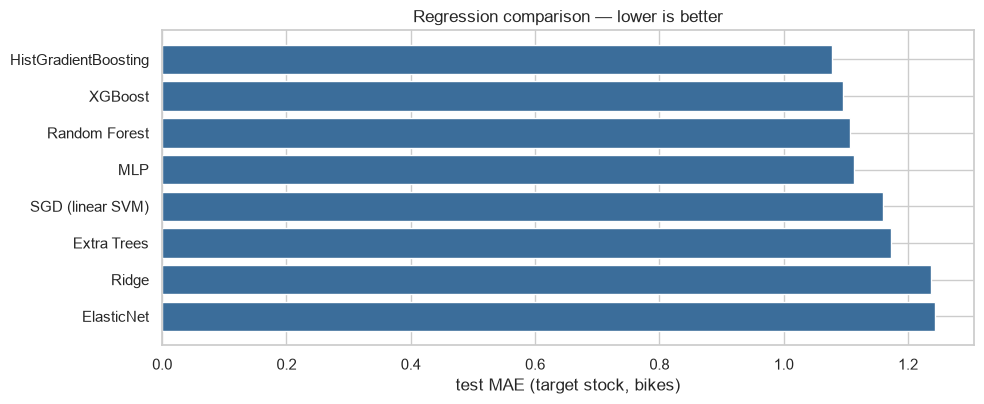

saved models to C:\Users\jejoz\Documents\Codigo\Cursos\TFG\v1\data\models


In [17]:
reg_rows = []
pred_store = {}
fitted_reg = {}

def _eval_reg(name, pred_val, pred_test, model=None):
    row = {"model": name}
    row.update({f"val_{k}": v for k, v in regression_metrics(y_val, pred_val, w_val).items()})
    row.update({f"test_{k}": v for k, v in regression_metrics(y_test, pred_test, w_test).items()})
    reg_rows.append(row)
    pred_store[name] = pred_test
    if model is not None:
        fitted_reg[name] = model
    print(name, {k: round(v, 3) for k, v in row.items() if k != "model"})

# --- original three ---
rf_reg = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("model", make_rf_regressor(RANDOM_SEED)),
])
rf_reg.fit(X_train, y_train)
_eval_reg("Random Forest", rf_reg.predict(X_val), rf_reg.predict(X_test), rf_reg)

xgb_reg = make_xgb_regressor(RANDOM_SEED)
try:
    xgb_reg.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
except TypeError:
    xgb_reg.fit(X_train, y_train)
_eval_reg("XGBoost", xgb_reg.predict(X_val), xgb_reg.predict(X_test), xgb_reg)

mlp_reg = make_mlp_regressor(RANDOM_SEED)
mlp_reg.fit(X_train, y_train)
_eval_reg("MLP", mlp_reg.predict(X_val), mlp_reg.predict(X_test), mlp_reg)
nn_reg_predict = mlp_reg.predict

# --- five additional families ---
extra_reg = [
    ("Ridge", make_ridge_regressor(RANDOM_SEED)),
    ("ElasticNet", make_elasticnet_regressor(RANDOM_SEED)),
    ("Extra Trees", make_extratrees_regressor(RANDOM_SEED)),
    ("HistGradientBoosting", make_hgb_regressor(RANDOM_SEED)),
    ("SGD (linear SVM)", make_linearsvr_regressor(RANDOM_SEED)),
]
for name, model in extra_reg:
    model.fit(X_train, y_train)
    _eval_reg(name, model.predict(X_val), model.predict(X_test), model)

reg_cmp = pd.DataFrame(reg_rows).round(3).sort_values("test_MAE")
display(reg_cmp)
best_reg_name = reg_cmp.iloc[0]["model"]
print("best regression by test MAE:", best_reg_name)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(reg_cmp["model"], reg_cmp["test_MAE"], color="#3b6d9a")
ax.set_xlabel("test MAE (target stock, bikes)")
ax.set_title("Regression comparison — lower is better")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

cfg.models_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(rf_reg, cfg.models_dir / f"rf_reg_{cfg.data_scope}.joblib")
joblib.dump(xgb_reg, cfg.models_dir / f"xgb_reg_{cfg.data_scope}.joblib")
print("saved models to", cfg.models_dir)


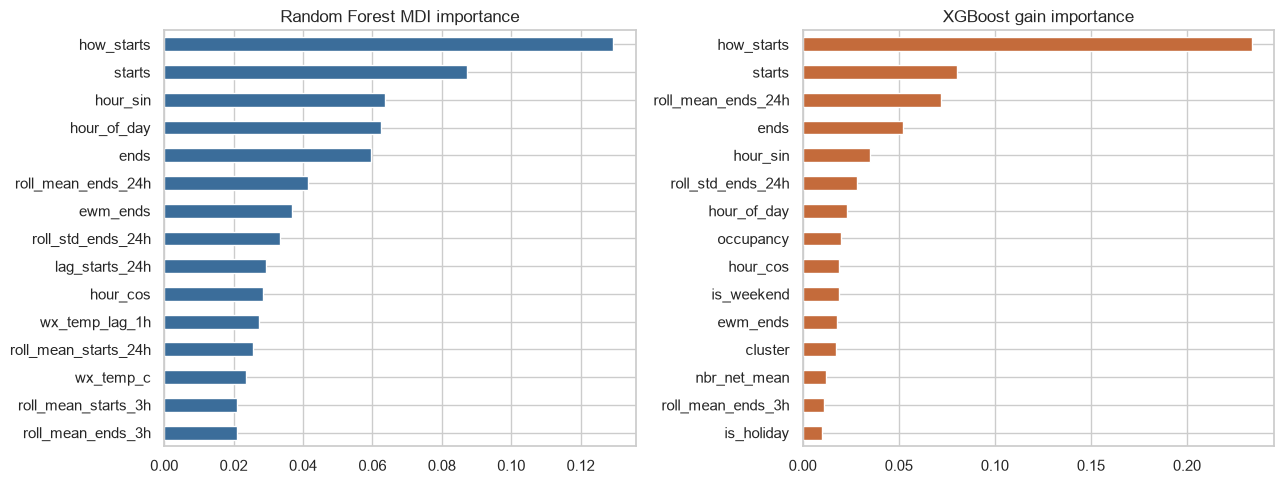

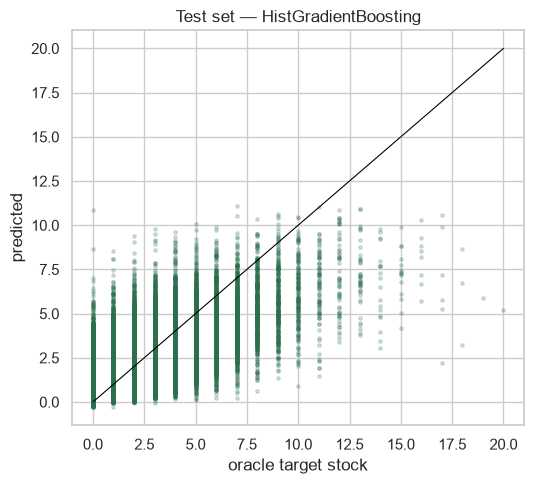

In [18]:
# Feature importance from the tree models
rf_imp = pd.Series(rf_reg.named_steps["model"].feature_importances_, index=feat_cols).sort_values(ascending=False)
xgb_imp = pd.Series(xgb_reg.feature_importances_, index=feat_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
rf_imp.head(15).iloc[::-1].plot.barh(ax=axes[0], color="#3b6d9a")
axes[0].set_title("Random Forest MDI importance")
xgb_imp.head(15).iloc[::-1].plot.barh(ax=axes[1], color="#c46b3b")
axes[1].set_title("XGBoost gain importance")
plt.tight_layout()
plt.show()

# Predicted vs actual on a slice of the test set
best_pred = pred_store[best_reg_name]
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test, best_pred, s=6, alpha=0.2, color="#2a6f4e")
lims = [0, max(y_test.max(), np.max(best_pred))]
ax.plot(lims, lims, color="black", lw=0.8)
ax.set_xlabel("oracle target stock")
ax.set_ylabel("predicted")
ax.set_title(f"Test set — {best_reg_name}")
plt.tight_layout()
plt.show()


### 8.2 Classification — will the station be empty or full in the next hour?


positive rate (critical) train/val/test: 0.09 0.07 0.1
Random Forest {'precision': 0.815, 'recall': 0.911, 'f1': 0.854, 'pr_auc': 0.883}
XGBoost {'precision': 0.794, 'recall': 0.92, 'f1': 0.841, 'pr_auc': 0.891}
MLP {'precision': 0.91, 'recall': 0.844, 'f1': 0.874, 'pr_auc': 0.868}
Logistic Regression {'precision': 0.793, 'recall': 0.866, 'f1': 0.824, 'pr_auc': 0.771}
Extra Trees {'precision': 0.835, 'recall': 0.888, 'f1': 0.859, 'pr_auc': 0.859}
HistGradientBoosting {'precision': 0.796, 'recall': 0.92, 'f1': 0.843, 'pr_auc': 0.891}
SGD SVM {'precision': 0.86, 'recall': 0.862, 'f1': 0.861, 'pr_auc': 0.763}
Decision Tree {'precision': 0.763, 'recall': 0.911, 'f1': 0.812, 'pr_auc': 0.867}


,model,precision,recall,f1,pr_auc
2,MLP,0.910,0.844,0.874,0.868
6,SGD SVM,0.860,0.862,0.861,0.763
4,Extra Trees,0.835,0.888,0.859,0.859
0,Random Forest,0.815,0.911,0.854,0.883
5,HistGradientBoosting,0.796,0.920,0.843,0.891
1,XGBoost,0.794,0.920,0.841,0.891
3,Logistic Regression,0.793,0.866,0.824,0.771
7,Decision Tree,0.763,0.911,0.812,0.867


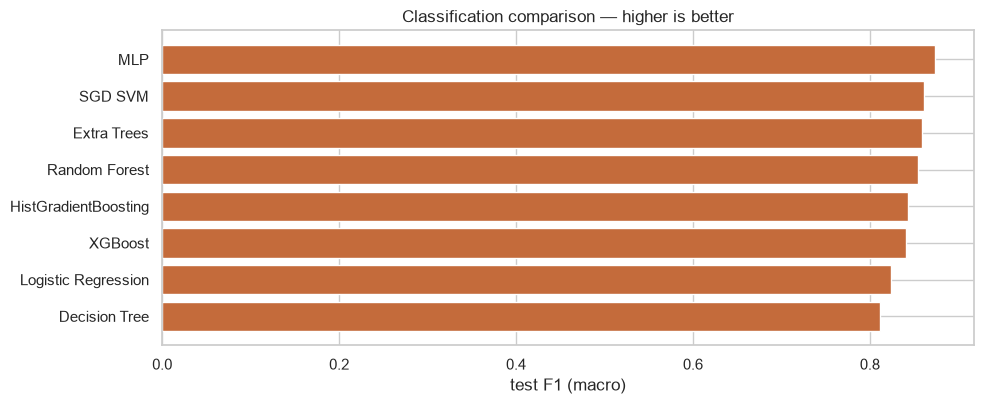

              precision    recall  f1-score   support

          ok       0.97      0.99      0.98     34937
    critical       0.85      0.70      0.77      3871

    accuracy                           0.96     38808
   macro avg       0.91      0.84      0.87     38808
weighted avg       0.96      0.96      0.96     38808



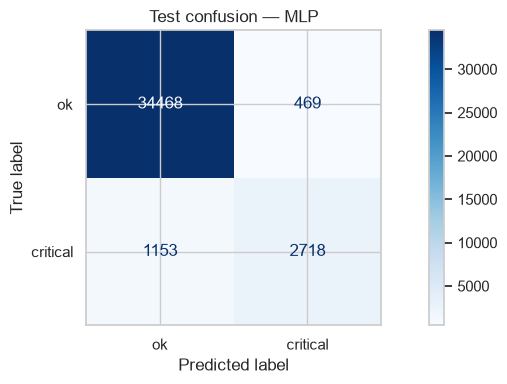

In [19]:
ytr_c = train_df["is_critical_next"].astype(int)
yva_c = val_df["is_critical_next"].astype(int)
yte_c = test_df["is_critical_next"].astype(int)
print("positive rate (critical) train/val/test:",
      ytr_c.mean().round(3), yva_c.mean().round(3), yte_c.mean().round(3))
pos = max(ytr_c.mean(), 1e-6)
scale = (1 - pos) / pos

clf_rows = []
clf_pred = {}

def _eval_clf(name, pred, proba):
    row = {"model": name, **classification_metrics(yte_c, pred, proba)}
    clf_rows.append(row)
    clf_pred[name] = (pred, proba)
    print(name, {k: round(v, 3) if isinstance(v, float) else v for k, v in row.items() if k != "model"})

rf_clf = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("model", make_rf_classifier(RANDOM_SEED)),
])
rf_clf.fit(X_train, ytr_c)
rf_p = rf_clf.predict_proba(X_test)
_eval_clf("Random Forest", rf_clf.predict(X_test), rf_p)

xgb_clf = make_xgb_classifier(RANDOM_SEED, scale_pos_weight=scale)
try:
    xgb_clf.fit(X_train, ytr_c, eval_set=[(X_val, yva_c)], verbose=False)
except TypeError:
    xgb_clf.fit(X_train, ytr_c)
xgb_p = xgb_clf.predict_proba(X_test)
_eval_clf("XGBoost", xgb_clf.predict(X_test), xgb_p)

mlp_clf = make_mlp_classifier(RANDOM_SEED)
mlp_clf.fit(X_train, ytr_c)
proba = mlp_clf.predict_proba(X_test)
_eval_clf("MLP", mlp_clf.predict(X_test), proba)

# --- five additional families ---
log_clf = make_logreg_classifier(RANDOM_SEED)
log_clf.fit(X_train, ytr_c)
_eval_clf("Logistic Regression", log_clf.predict(X_test), log_clf.predict_proba(X_test))

et_clf = make_extratrees_classifier(RANDOM_SEED)
et_clf.fit(X_train, ytr_c)
_eval_clf("Extra Trees", et_clf.predict(X_test), et_clf.predict_proba(X_test))

hgb_clf = make_hgb_classifier(RANDOM_SEED)
hgb_clf.fit(X_train, ytr_c)
_eval_clf("HistGradientBoosting", hgb_clf.predict(X_test), hgb_clf.predict_proba(X_test))

svc_clf = make_linearsvc_classifier(RANDOM_SEED)
svc_clf.fit(X_train, ytr_c)
svc_scores = svc_clf.decision_function(X_test)
_eval_clf("SGD SVM", svc_clf.predict(X_test), scores_to_proba(svc_scores))

tree_clf = make_adaboost_classifier(RANDOM_SEED)
tree_clf.fit(X_train, ytr_c)
_eval_clf("Decision Tree", tree_clf.predict(X_test), tree_clf.predict_proba(X_test))

clf_cmp = pd.DataFrame(clf_rows).round(3).sort_values("f1", ascending=False)
display(clf_cmp)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(clf_cmp["model"], clf_cmp["f1"], color="#c46b3b")
ax.set_xlabel("test F1 (macro)")
ax.set_title("Classification comparison — higher is better")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

best_clf_name = clf_cmp.iloc[0]["model"]
pred_best, _ = clf_pred[best_clf_name]
print(classification_report(yte_c, pred_best, target_names=["ok", "critical"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(yte_c, pred_best, display_labels=["ok", "critical"], cmap="Blues")
plt.title(f"Test confusion — {best_clf_name}")
plt.tight_layout()
plt.show()


## 9. Downstream evaluation: bike utilization rate

MAE on `target_stock` is an intermediate number. The quantity in the project statement is **utilization**, plus the lost-start / lost-end counts that explain it.

We replay the **test** hours under three inventory policies, using *realized* next-hour demand (the fairest comparison of stock policies):

1. **Observed stock** — what BiciMAD actually had (includes whatever rebalancing already happened).
2. **Predicted target stock, perfect rebalancing** — snap every station to the model’s `target_stock` (upper bound on the value of predictions).
3. **Oracle target stock, perfect rebalancing** — the label itself (upper bound on the value of *information*).

Section 10 adds a fourth policy: stocks reachable with a **finite truck**.


,policy,lost_starts,lost_ends,served_starts,start_service_rate,end_service_rate
0,observed (no extra rebalancing),5064.0,1490.0,63008.0,0.926,0.978
1,oracle target stock (perfect foresight + perfe...,217.0,1.0,67855.0,0.997,1.000
2,predicted target stock (perfect rebalancing),18703.0,74.0,49369.0,0.725,0.999


Observed fleet utilization U ≈ 0.0357 (3.57%)
Service rates above are the lever: closing lost starts raises the numerator of U.


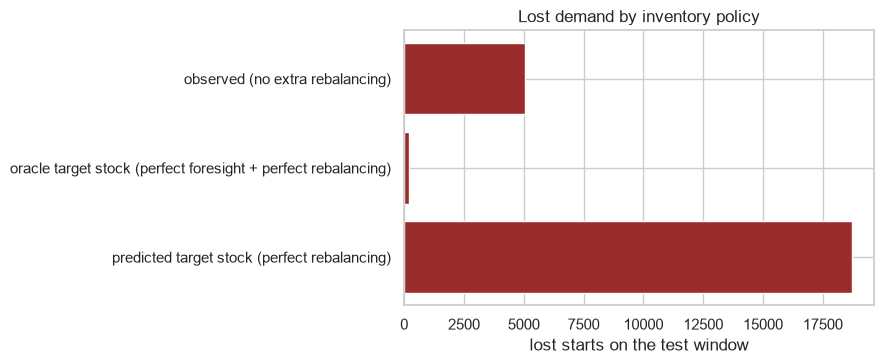

In [20]:
test_eval = test_df.copy()
cap = test_eval["capacity"].fillna(test_eval["total_bases"]).clip(lower=1)
pred_stock = np.clip(np.rint(pred_store[best_reg_name]), 0, cap)

# Auxiliary starts/ends predictions from the same best model family, trained quickly on starts_next / ends_next
_AUX_FACTORY = {
    "Random Forest": lambda: Pipeline([("impute", SimpleImputer(strategy="median")), ("model", make_rf_regressor(RANDOM_SEED))]),
    "XGBoost": lambda: make_xgb_regressor(RANDOM_SEED),
    "Ridge": lambda: make_ridge_regressor(RANDOM_SEED),
    "ElasticNet": lambda: make_elasticnet_regressor(RANDOM_SEED),
    "Extra Trees": lambda: make_extratrees_regressor(RANDOM_SEED),
    "HistGradientBoosting": lambda: make_hgb_regressor(RANDOM_SEED),
    "SGD (linear SVM)": lambda: make_linearsvr_regressor(RANDOM_SEED),
    "MLP": lambda: make_mlp_regressor(RANDOM_SEED),
}

def _fit_aux(ycol):
    ytr = train_df[ycol]
    factory = _AUX_FACTORY.get(best_reg_name)
    if factory is None:
        return nn_reg_predict(X_test)
    m = factory()
    # sklearn>=1.4 Pipelines raise ValueError (not TypeError) on eval_set.
    # XGBoost is the only family that needs a validation set: early stopping is on.
    if best_reg_name == "XGBoost":
        try:
            m.fit(X_train, ytr, eval_set=[(X_val, val_df[ycol])], verbose=False)
        except TypeError:
            m.fit(X_train, ytr, eval_set=[(X_val, val_df[ycol])])
    else:
        m.fit(X_train, ytr)
    return m.predict(X_test)

test_eval["starts_hat"] = np.clip(_fit_aux("starts_next"), 0, None)
test_eval["ends_hat"] = np.clip(_fit_aux("ends_next"), 0, None)
test_eval["pred_stock"] = pred_stock

policy_table = simulate_policies(test_eval, predicted_stock=test_eval["pred_stock"])
display(policy_table.round(3))

# Approximate utilization under served starts: scale observed U by served-start rate
u_obs = U["utilization"]
served_obs = policy_table.loc[policy_table["policy"].str.contains("observed"), "start_service_rate"].iloc[0]
print(f"Observed fleet utilization U ≈ {u_obs:.4f} ({100*u_obs:.2f}%)")
print("Service rates above are the lever: closing lost starts raises the numerator of U.")

fig, ax = plt.subplots(figsize=(9, 3.8))
plot_p = policy_table.copy()
ax.barh(plot_p["policy"], plot_p["lost_starts"], color="#9b2c2c")
ax.set_xlabel("lost starts on the test window")
ax.set_title("Lost demand by inventory policy")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


## 10. Linear programming — periodic redistribution

Machine learning says *how many bikes each station wants*. Trucks decide *which bikes actually move*. That second problem is a linear program.

**Decision variables** $x_{ij} \ge 0$: bikes moved from station $i$ to station $j$ in one operational window (here: a morning-peak hour on the test set).

**Inventory balance**

$$
s_i = b_i - \sum_j x_{ij} + \sum_j x_{ji}, \qquad 0 \le s_i \le C_i.
$$

**Pooled truck capacity** (documented simplification of multi-vehicle routing)

$$
\sum_{i,j} x_{ij} \le Q.
$$

**Linear objective** — expected lost starts and lost ends from the *predicted* demand, plus a small distance cost so the solver does not ship bikes across Madrid for a 0.01 gain:

$$
\min \sum_i \bigl[
\lambda_e \max(0, \hat{a}_i - s_i)
+ \lambda_f \max(0, \hat{r}_i - (C_i - s_i))
\bigr]
+ \gamma \sum_{i,j} d_{ij} x_{ij}.
$$

We solve it with PuLP + CBC on the cluster (or the 25 most imbalanced stations) so the move list is readable. The same formulation scales to the full 264-station network.


LP window: 2022-10-26 07:00:00+02:00 stations: 264
solving on 82 stations
status: Optimal objective: 0.01 bikes moved: 0.1 arcs: 1
lost starts after LP: 0.0 lost ends: 0.0


,from_id,to_id,bikes,km,from_name,to_name
0,112,100,0.11,0.26,Colón B,Villanueva


,name,dock_bikes,capacity,starts_hat,ends_hat,lp_stock,delta
station_id,,,,,,,
100,Villanueva,0,24,0.11,0.35,0.11,0.11
112,Colón B,2,18,0.11,0.29,1.89,-0.11
98,Plaza de Colón,0,24,0.01,0.36,0.01,0.01
111,Colón A,1,18,0.04,0.31,0.99,-0.01
105,Palacio de Deportes,1,24,0.11,0.34,0.99,-0.01
96,Príncipe de Vergara,0,24,0.01,0.13,0.01,0.01
269,Facultad Derecho,3,24,0.23,0.44,3.00,-0.0
268,Facultad Biología,0,24,0.00,0.13,0.00,0.0
150,Raimundo Fernández,10,24,0.55,0.25,10.00,-0.0


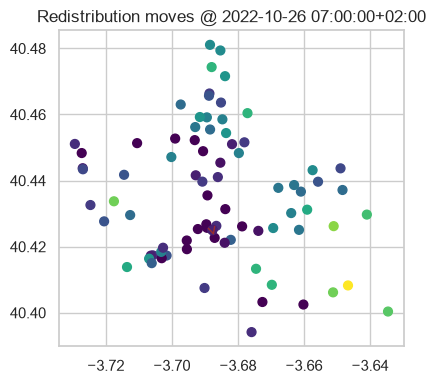

Policies on the single LP hour (2022-10-26 07:00:00+02:00)


,policy,lost_starts,lost_ends,served_starts,start_service_rate,end_service_rate
0,observed (no extra rebalancing),1.0,0.0,117.0,0.992,1.0
1,oracle target stock (perfect foresight + perfe...,0.0,0.0,118.0,1.000,1.0
2,predicted target stock (perfect rebalancing),42.0,0.0,76.0,0.644,1.0
3,LP rebalancing (truck capacity),1.0,0.0,117.0,0.992,1.0


In [21]:
# Pick one morning-peak hour in the test set with complete occupancy
candidates = test_eval[test_eval["hour_of_day"].eq(7) & test_eval["dock_bikes"].notna()].copy()
hour_counts = candidates.groupby("hour").size().sort_values(ascending=False)
lp_hour = hour_counts.index[0]
snap = candidates[candidates["hour"].eq(lp_hour)].copy()
print("LP window:", lp_hour, "stations:", len(snap))

# Stations with the largest gap between current stock and predicted need
snap["rebalance_gap"] = (snap["pred_stock"] - snap["dock_bikes"]).abs()
if snap["cluster"].nunique() > 1:
    cl_score = snap.assign(_c=snap["is_empty"] + snap["is_full"]).groupby("cluster")["_c"].mean()
    focus = snap[snap["cluster"].eq(cl_score.idxmax())].copy()
    if len(focus) < 8:
        focus = snap.nlargest(25, "rebalance_gap")
else:
    focus = snap.nlargest(min(25, len(snap)), "rebalance_gap")

focus = focus.drop_duplicates("station_id")
print("solving on", len(focus), "stations")

lp = redistribution_lp(
    focus.rename(columns={"starts_hat": "starts_hat", "ends_hat": "ends_hat"}),
    truck_capacity=40,
    empty_penalty=8.0,
    full_penalty=6.0,
    move_cost_per_km=0.15,
)
print("status:", lp["status"], "objective:", round(lp["objective"] or 0, 2),
      "bikes moved:", round(lp["bikes_moved"], 1), "arcs:", lp["n_arcs"])
print("lost starts after LP:", round(lp["lost_starts"], 2), "lost ends:", round(lp["lost_ends"], 2))

moves = lp["moves"]
if len(moves):
    names = catalog.set_index("station_id")["name"]
    moves["from_name"] = moves["from_id"].map(names)
    moves["to_name"] = moves["to_id"].map(names)
    display(moves.sort_values("bikes", ascending=False).head(15))
else:
    print("No moves — predicted demand already matches inventory, or truck cost dominates.")

# Before / after occupancy for the subset
before = focus.set_index("station_id")[["name", "dock_bikes", "capacity", "starts_hat", "ends_hat"]]
after = lp["stock_after"].rename("lp_stock")
cmp = before.join(after)
cmp["delta"] = cmp["lp_stock"] - cmp["dock_bikes"]
display(cmp.reindex(cmp["delta"].abs().sort_values(ascending=False).index).head(12).round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(focus["lon"], focus["lat"], s=40, c=focus["dock_bikes"], cmap="viridis", zorder=2)
if len(moves):
    coords = focus.set_index("station_id")[["lon", "lat"]]
    for _, m in moves.iterrows():
        if m["from_id"] in coords.index and m["to_id"] in coords.index:
            x0, y0 = coords.loc[m["from_id"]]
            x1, y1 = coords.loc[m["to_id"]]
            ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                        arrowprops=dict(arrowstyle="->", color="#9b2c2c", lw=1 + 0.15 * m["bikes"]))
ax.set_title(f"Redistribution moves @ {lp_hour}")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

# Attach LP stocks onto the single-hour slice for policy comparison
hour_slice = test_eval[test_eval["hour"].eq(lp_hour)].copy()
hour_slice["lp_stock_col"] = hour_slice["station_id"].map(lp["stock_after"]).fillna(hour_slice["dock_bikes"])
hour_policies = simulate_policies(
    hour_slice,
    predicted_stock=hour_slice["pred_stock"],
    lp_stock=hour_slice["lp_stock_col"],
)
print(f"Policies on the single LP hour ({lp_hour})")
display(hour_policies.round(3))


## 11. Conclusions

**What the pipeline established**

- BiciMAD’s public history is three schemas, hourly status, and a growing station map. Treating it as a single CSV is how analyses go wrong; the adapters, quality report, Pandera gates, and parquet checkpoints are the actual data product.
- The quantity to maximize is **bike utilization rate** $U$. Empty/full station-hours and lost starts/ends are the operational levers that move $U$.
- The right ML target is the **stock** each station needs next hour, with a parallel **criticality** classifier for alerts.
- Compare all eight model families on MAE *and* on lost demand. Linear baselines (Ridge, ElasticNet, SGD) quantify how much the trees actually buy; the model that wins MAE is not automatically the one that lifts $U$.
- Linear programming turns predicted stocks into a feasible truck plan. The gap between “perfect rebalancing” and an LP with $Q = 40$ is the value of more trucks (or better routing), not of more trees.

**Limitations**

- Hourly grain is native, not a choice. GPS tracks were dropped for performance; they are a separate mobility thesis.
- Weather is district-centroid reanalysis (Open-Meteo ERA5), not AEMET station observations. Adjacent central districts can share a grid cell.
- Mass events cover major football/concert/fair/rally venues, not every neighbourhood fiesta. Attendance is sometimes press-estimated.
- The LP uses a **pooled truck capacity**, not a multi-vehicle VRP with time windows.
- `stations_static/` is empty; metadata comes from status snapshots.

**Natural extensions**

- LSTM / TCN on per-station occupancy sequences, or a small GNN on the trip graph.
- Multi-period LP (several windows, bikes in transit).
- A live EMT API client so the same feature store scores tonight’s 06:00 plan.
